In [51]:


import json, math, warnings

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'models' / 'src'))
from common import paths, plots
from common.data import read_csv, show_dataset
from common.plots import (SUPERFICIE, TINTA, TINTA_2, PREDITO, enfeitar, plot_time_series)

plots.aplicar_estilo()



SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
NL = chr(10)   # evita barra invertida no fonte; usado nos relatorios


DATA_DIR = paths.RAW
IMG_DIR = paths.ROOT / 'docs' / 'figuras'

print(f"dados em {DATA_DIR}")
print(f"semente: {SEED}")

dados em C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\raw
semente: 42


In [52]:
ARQUIVOS = (
    sorted(DATA_DIR.rglob("ifpee*.csv"))
)

print(f"{len(ARQUIVOS)} arquivos" + NL)

partes = []
for p in ARQUIVOS:
    df = read_csv(p)
    df['station'] = p.stem.split('_')[0]
    partes.append(df)
    print(f"  {p.parent.name:10} {p.stem:16} {len(df):7} linhas  {len(df.columns):2} colunas")

raw: pd.DataFrame = pd.concat(partes, ignore_index=True)

9 arquivos

  raw        ifpee1_2021        45872 linhas  18 colunas
  raw        ifpee1_2022        43750 linhas  18 colunas
  raw        ifpee1_2023        46380 linhas  18 colunas
  raw        ifpee1_2024        46514 linhas  19 colunas
  raw        ifpee1_2025        44969 linhas  19 colunas
  raw        ifpee2_2024        46514 linhas  19 colunas
  raw        ifpee2_2025        44969 linhas  19 colunas
  raw        ifpee3_2024        46514 linhas  19 colunas
  raw        ifpee3_2025        44969 linhas  19 colunas


In [53]:

# remover colunas "mortas"
REMOVE_COLS = {"ano", 'velocidade_vento', 'condicao' }
raw = raw.drop(columns=[c for c in REMOVE_COLS if c in raw.columns])

df = show_dataset(
  raw
    .copy()
    .dropna(subset=['PCA'])
    .reset_index(drop=True)
) 


pool: 410375 linhas, 17 colunas

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA    9607


In [ ]:
# Cleanup dataset
outages = (df.PCA == 0) & (df.ghit > 50)
clipping = (df.PCA >= 2)
low_irradiance = (df.ghit < 5)
high_temperature = (df.temp_amb >= 50)

invalid = (
  outages | clipping | low_irradiance | high_temperature | low_temperature
)

df = df[~invalid]

df = show_dataset(df.reset_index(drop=True))


pool: 401084 linhas, 17 colunas

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA    1057


In [41]:
numeric_cols = df.select_dtypes(include="number").columns

summary_stats = (
  df.groupby("station")[numeric_cols]
    .agg(["min", "max", "mean", "std"])
)

summary_stats

temp_amb                              doy                                  ghi_cs                                       hora_dec                                       kc                      \
             min     max       mean       std min  max        mean         std        min          max        mean         std       min        max       mean       std      min       max      mean   
station                                                                                                                                                                                                 
ifpee1     6.338  40.786  27.432452  4.140114   1  366  184.030857  107.867487  79.332931  1066.308609  662.585266  285.737148  5.779167  17.116667  11.473503  3.069995  0.00851  8.761781  0.769084   
ifpee2     6.338  40.786  27.703888  4.241428   1  366  183.776670  108.757322  79.332931  1066.308609  663.481096  285.957044  5.783333  17.116667  11.466507  3.066804  0.00851  8.761781  0.809766   
ifpee3     6.338  40.786  27.702001  4.242124   1  366  183.810016  108.765448  79.332931  1066.308609  663.249622  285.971344  5.783333  17.116667  11.465726  3.067871  0.00851  8.761781  0.809702   

                     angzen                                       ghit                                       PCA                              jacques                                      sandia  \
              std       min        max       mean        std       min          max        mean         std  min   max      mean       std        min        max       mean        std        min   
station                                                                                                                                                                                             
ifpee1   0.337126  0.134047  79.999981  44.207435  20.181832  5.015856  1583.257158  516.620616  334.990408  0.0  1.99  0.921820  0.559917  11.031228  75.964472  41.116951  12.135459  10.894606   
ifpee2   0.348446  0.134047  79.999951  44.133237  20.219351  5.016667  1583.257158  546.448466  352.318974  0.0  1.99  0.888989  0.541237  11.031228  76.510643  42.332461  12.593866  10.894606   
ifpee3   0.348383  0.134047  79.999951  44.151864  20.215232  5.016667  1583.257158  546.139293  352.070808  0.0  1.99  0.906798  0.553637  11.031228  76.510643  42.322297  12.587904  10.894606   

                                         sandia_cell                                  pvsyst_cell                                         ioeff                                             kt  \
               max       mean        std         min        max       mean        std         min        max       mean        std          min          max         mean        std       min   
station                                                                                                                                                                                          
ifpee1   74.730641  40.697250  11.911011   12.319189  87.596033  44.880910  14.554453   11.234698  77.802010  41.862201  12.452522  1321.019638  1411.180883  1367.996072  31.634976  0.005853   
ifpee2   75.331593  41.906610  12.328754   12.319189  87.625774  46.346979  15.109840   11.234698  78.266596  42.966759  12.989278  1321.019638  1411.180883  1368.488310  31.874365  0.005853   
ifpee3   75.331593  41.896687  12.322992   12.319189  87.625774  46.334543  15.102003   11.234698  78.266596  42.956236  12.983019  1321.019638  1411.180883  1368.490697  31.879752  0.005853   

                                       
              max      mean       std  
station                                
ifpee1   4.457725  0.528785  0.238883  
ifpee2   4.457725  0.557506  0.248763  
ifpee3   4.457725  0.557397  0.248673

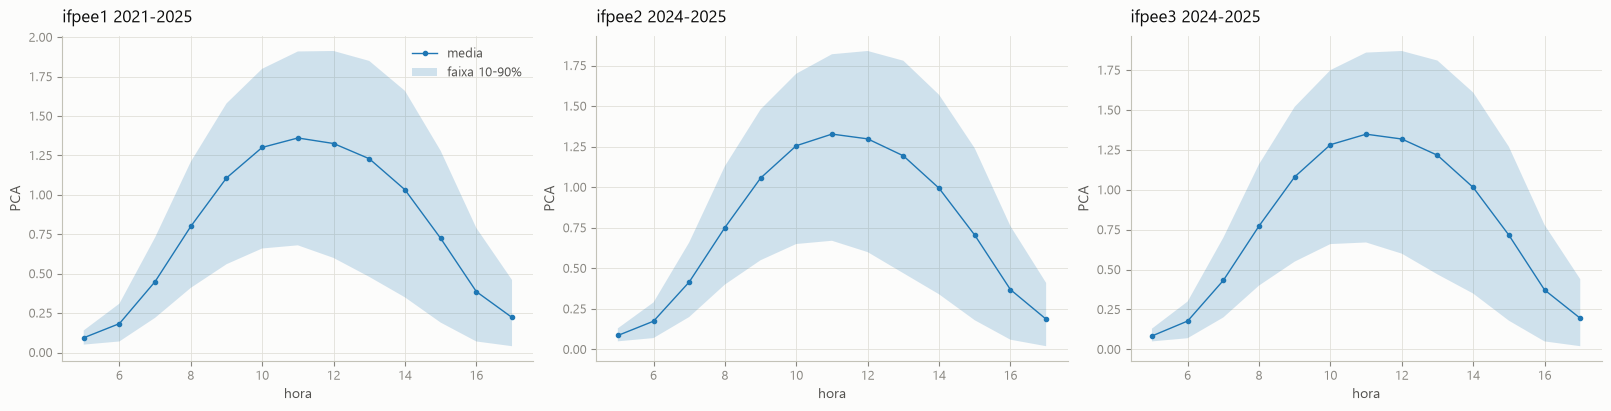

In [42]:
d2 = df.copy()

d2["hora"] = d2.datetime.dt.hour

# 1) PCA por hora do dia, uma estacao por painel (media + faixa 10-90%)
lines = (len(d2.station.unique()) / 2).__round__()
fig, axs = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for ax, (nome, d) in zip(axs.flat, d2.groupby("station")):
    g = d.groupby("hora")["PCA"]
    ax.plot(g.mean().index, g.mean().values, marker=".", lw=1, label="media")
    ax.fill_between(g.mean().index, g.quantile(0.1).values, g.quantile(0.9).values,
                    alpha=0.2, label="faixa 10-90%")
    enfeitar(ax, f"{nome} {d.datetime.dt.year.min()}-{d.datetime.dt.year.max()}", "hora", "PCA")
axs.flat[0].legend(frameon=False, fontsize=9, labelcolor=TINTA_2)
_ = fig.savefig(IMG_DIR / "pca_por_hora_do_dia.png")

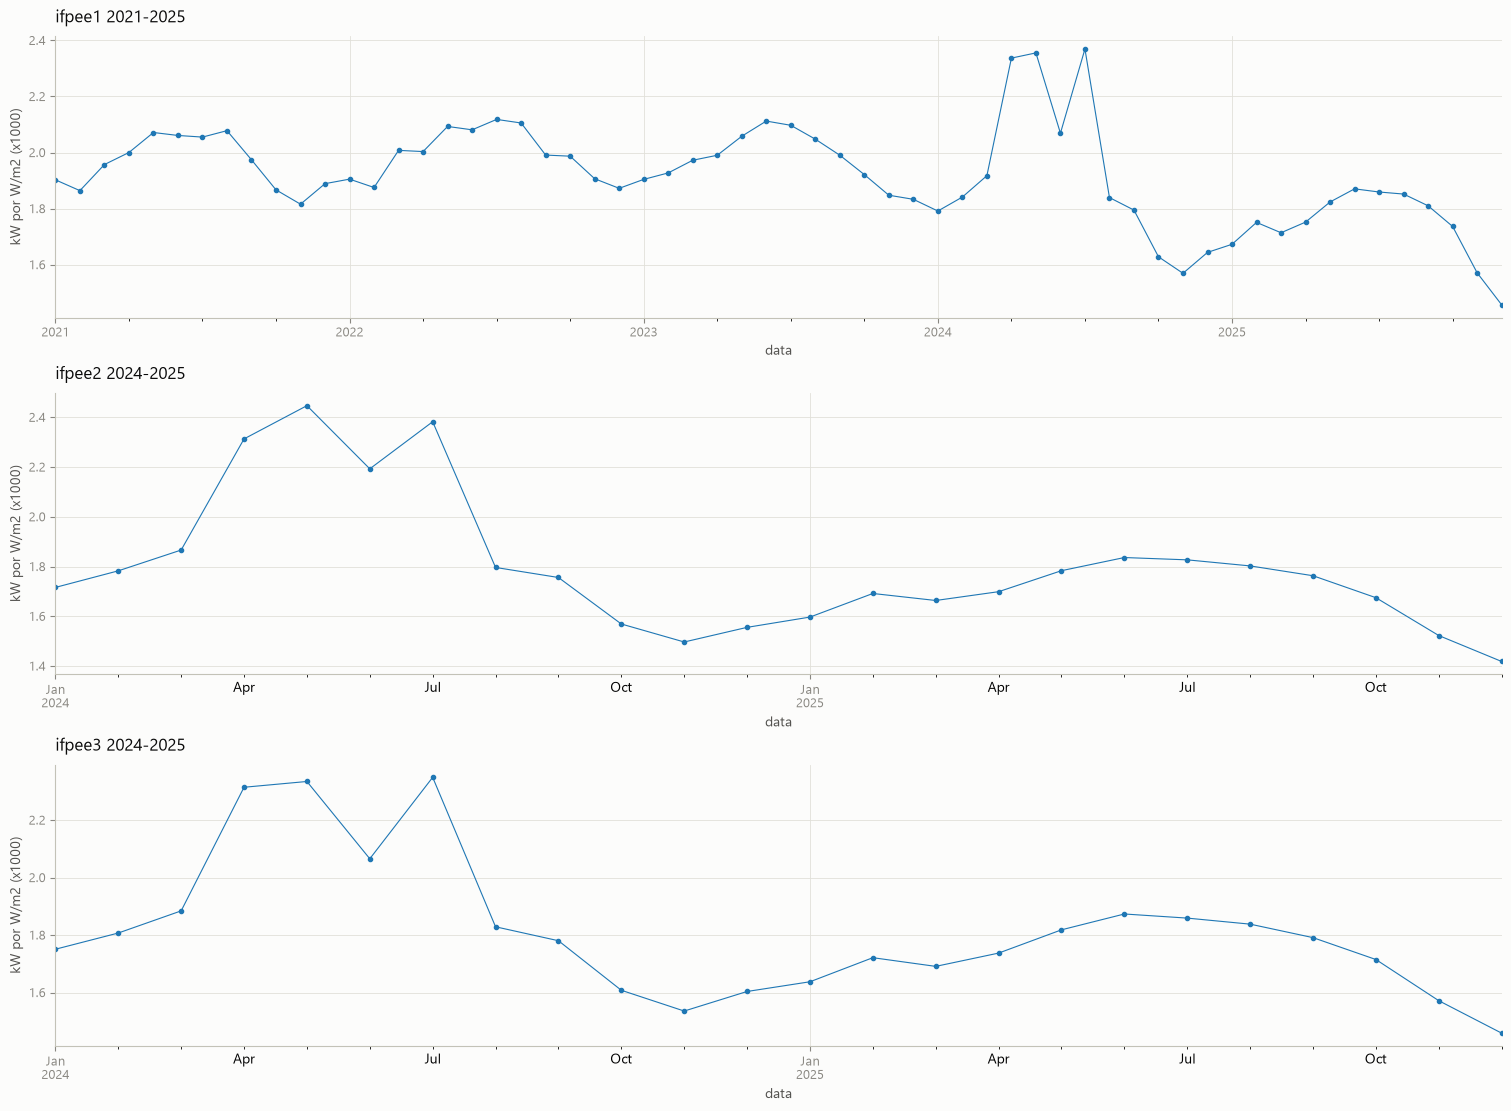

In [43]:
# 4) Eficiencia do sistema PCA / ghit (media diaria, x1000), uma estacao por painel.
# A razao cancela a sazonalidade de sol; o que sobra e' o estado do sistema.
fig, axs = plt.subplots(3, 1, figsize=(15, 11), constrained_layout=True)
for ax, (nome, d) in zip(axs.flat, d2.groupby("station")):
    dd = d[(d.PCA != 0) & (d.ghit > 0)]
    dd['ef'] = dd.PCA / dd.ghit
    dd = dd.groupby(dd["datetime"].dt.to_period("M")).agg({
        'ef': 'mean',
        'datetime': 'first'
    })
    ef = dd.ef
    (ef * 1000).plot(ax=ax, marker=".", lw=0.8)
    enfeitar(ax, f"{nome} {dd.datetime.dt.year.min()}-{dd.datetime.dt.year.max()}", "data", "kW por W/m2 (x1000)")
# fig.suptitle("Produtividade do sistema: PCA / ghit", color=TINTA, fontsize=13)
fig.savefig(IMG_DIR / "produtividade.png")
del d2

In [44]:
plot_time_series(df.reset_index(), janela='1d', freq="5min")


KeyboardInterrupt: 

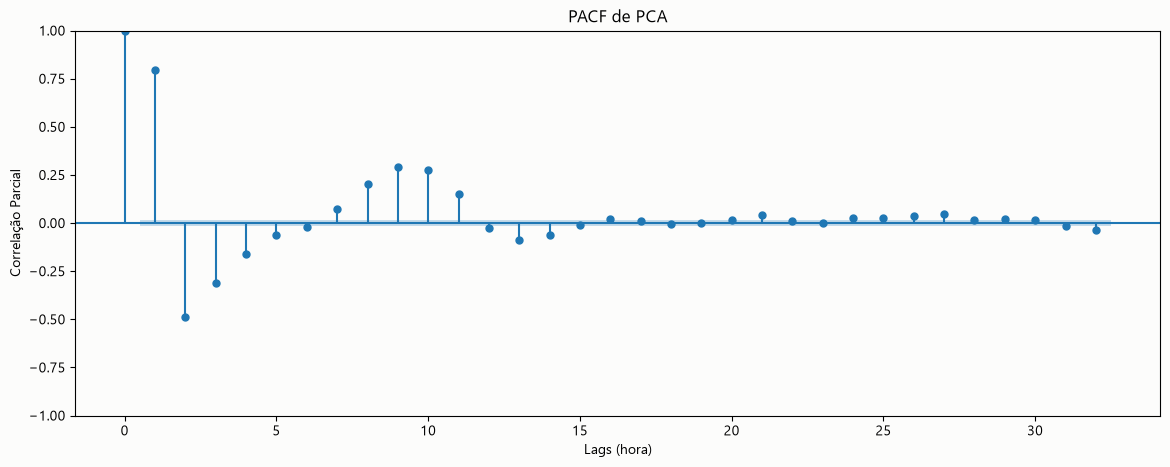

In [ ]:
from statsmodels.graphics.tsaplots import plot_pacf

df_a = df.copy()  # remove 2024, que tem perda de dados
PCA = df_a.groupby([pd.Grouper(key='datetime', freq='1h')]).PCA.mean().dropna()


fig, ax = plt.subplots(figsize=(14, 5))
plot_pacf(PCA, ax=ax, lags=32, method="ywm", title="PACF de PCA")


# 3. Exibindo o gráfico
ax.set_xlabel("Lags (hora)")
ax.set_ylabel("Correlação Parcial")

plt.show()

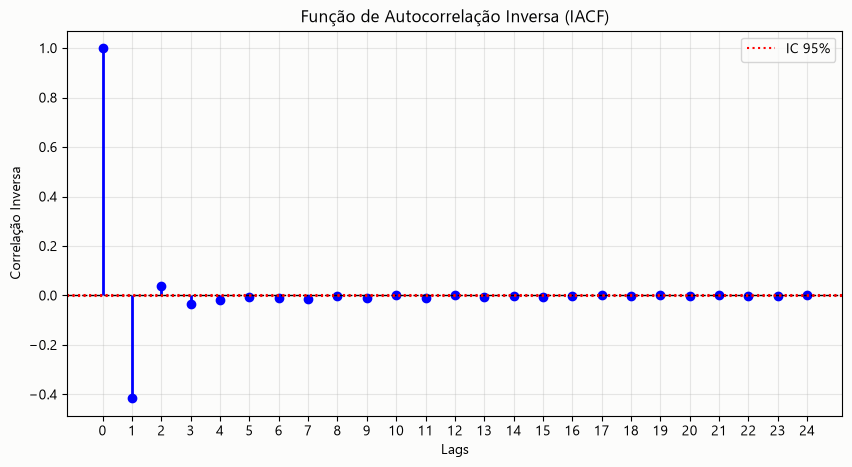

In [ ]:
from statsmodels.regression.linear_model import yule_walker

def plot_iacf(series, lags=20):
    """
    Calcula e plota a Função de Autocorrelação Inversa (IACF)
    baseada na aproximação por um modelo autorregressivo de alta ordem.
    """
    # Remove valores nulos caso existam na série do Pandas
    series = series.dropna()
    n = len(series)
    
    # 1. Ajusta um modelo AR de alta ordem (Yule-Walker)
    # Geralmente usa-se a ordem sugerida pela metade das observações ou um limite prático
    ar_order = min(lags * 2, n // 3)
    ar_coefs, _ = yule_walker(series, order=ar_order, demean=True)
    
    # 2. Convoluciona os coeficientes AR com eles mesmos para obter a IACF aproximada
    # Adiciona 1 no início para representar o lag 0
    ar_operator = np.r_[1, -ar_coefs]
    iacf_raw = np.correlate(ar_operator, ar_operator, mode='full')
    
    # Pega apenas a metade positiva (lags de 0 em diante)
    iacf = iacf_raw[len(iacf_raw)//2 : len(iacf_raw)//2 + lags + 1]
    
    # Normaliza para que o lag 0 seja igual a 1
    iacf = iacf / iacf[0]

    # Remove lags muito baixos para evitar ruído visual (opcional)
    # iacf = np.where(np.abs(iacf) < 0.1, 0, iacf)
    
    # 3. Monta o gráfico no estilo clássico do statsmodels
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Plota as barras verticais para os lags de 1 até o limite definido
    x_lags = np.arange(len(iacf))
    ax.vlines(x_lags, 0, iacf, colors='b', lw=2)
    ax.plot(x_lags, iacf, 'bo')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    
    # Limites de significância estatística aproximados (IC de 95%)
    conf_level = 1.96 / np.sqrt(n)
    ax.axhline(conf_level, color='red', linestyle=':', label='IC 95%')
    ax.axhline(-conf_level, color='red', linestyle=':')
    
    ax.set_title("Função de Autocorrelação Inversa (IACF)")
    ax.set_xlabel("Lags")
    ax.set_ylabel("Correlação Inversa")
    ax.set_xticks(x_lags)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_iacf(df.PCA, lags=24)

In [ ]:
import pandas as pd
def downsample(df: pd.DataFrame, interval: str):
    d = df.copy() 
    invalid = (
        (d.PCA == 0) | (d.ghit < 10) | 
        (d.temp_amb > 50) | 
        (d.PCA > 1.95)
    )
    d.drop(d[invalid].index, inplace=True)
    d = d.reset_index(drop=True)
    d = d.groupby(['datetime']).agg({'PCA': 'mean'})
    d = d[d.isna().sum(axis=1) == 0].reset_index()
    
    a = d.groupby(pd.Grouper(key="datetime", freq=interval))
    d = a.filter(lambda group: group["PCA"].ne(0).all())

    return d.groupby(pd.Grouper(key="datetime", freq=interval)).agg({'PCA': 'mean'})


In [ ]:
intervals = ('5min', '10min', '30min', '1h', '6h', '1D')
frames = { interval: downsample(df, interval) for interval in intervals}

C:\Users\gusta\AppData\Local\Temp\ipykernel_10792\1855114184.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  d.drop(d[invalid].index, inplace=True)


C:\Users\gusta\AppData\Local\Temp\ipykernel_10792\3097727739.py:18: UserWarning: The figure layout has changed to tight
  fig.tight_layout(pad=3, h_pad=1.5)
C:\Users\gusta\AppData\Local\Temp\ipykernel_10792\3097727739.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


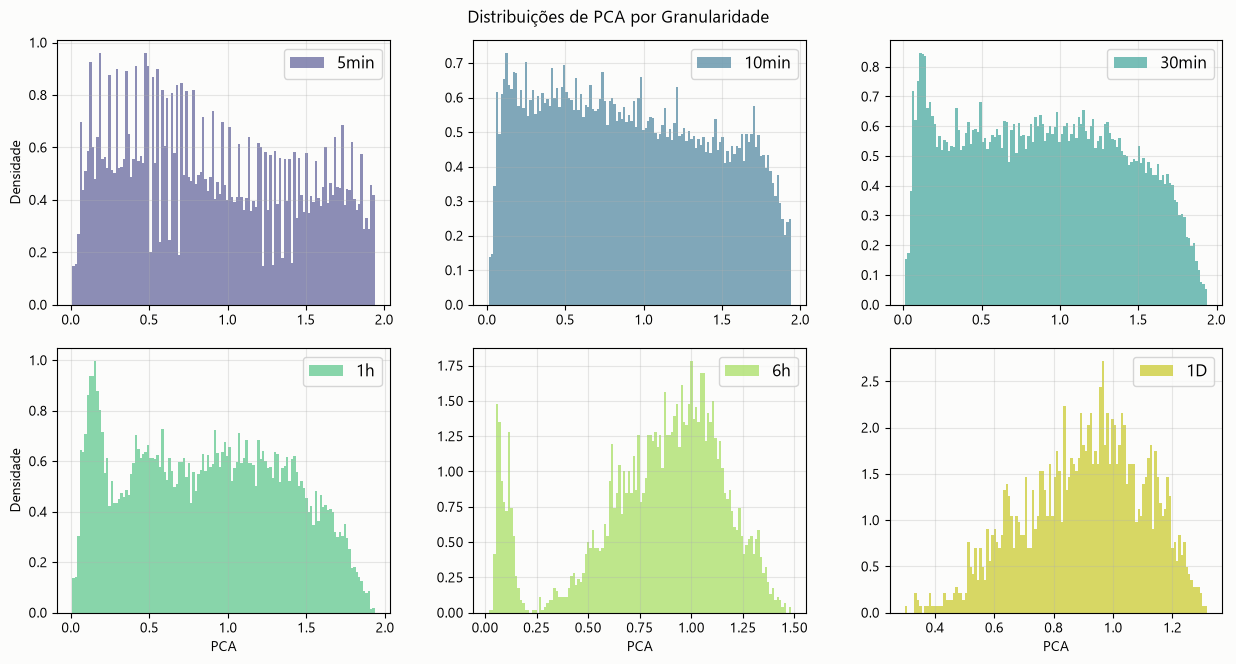

In [ ]:
fig, ax = plt.subplots(figsize=(13, 7), ncols=3, nrows=2, constrained_layout=True)

cores = plt.cm.viridis(np.linspace(0.2, 1.0, 6)).tolist()
cores[-1] = 'y'

for freq, d2, ax, c in zip(intervals, frames.values(), ax.flat, cores):
  ax.hist(d2[d2.PCA > 0].PCA, bins=126, density=True, alpha=0.6, label=freq, color=c)
  ax.legend(loc="upper right", fontsize=12)
  
  if freq in intervals[3:]:
    ax.set_xlabel("PCA")

  if freq in (intervals[0], intervals[3]):
    ax.set_ylabel("Densidade")
  
  ax.grid(alpha=0.3)

fig.tight_layout(pad=3, h_pad=1.5)
fig.suptitle("Distribuições de PCA por Granularidade")
fig.show()

C:\Users\gusta\AppData\Local\Temp\ipykernel_10792\4193963325.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


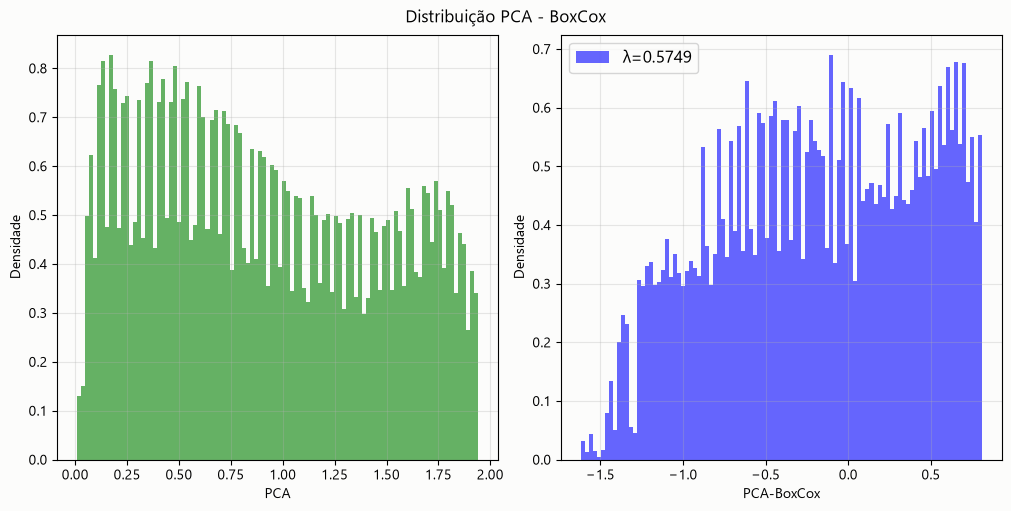

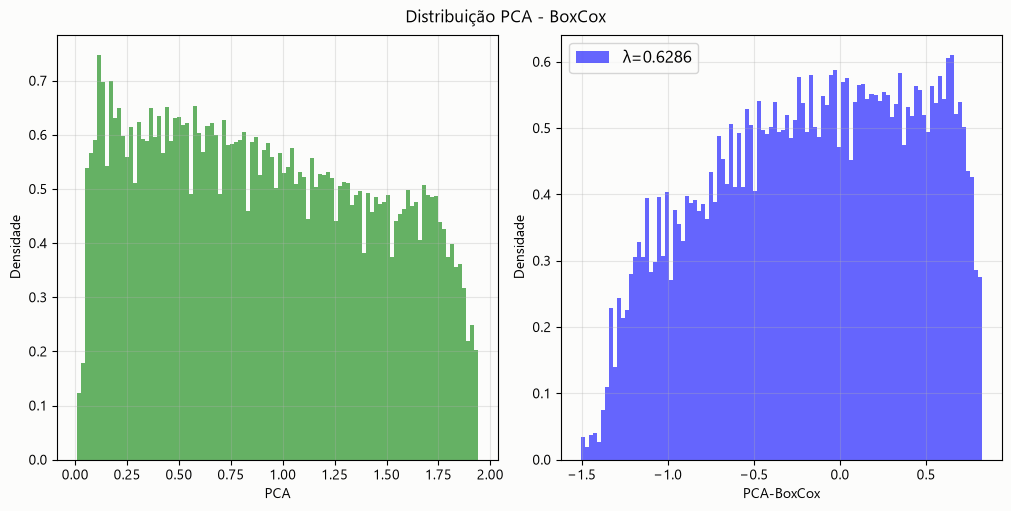

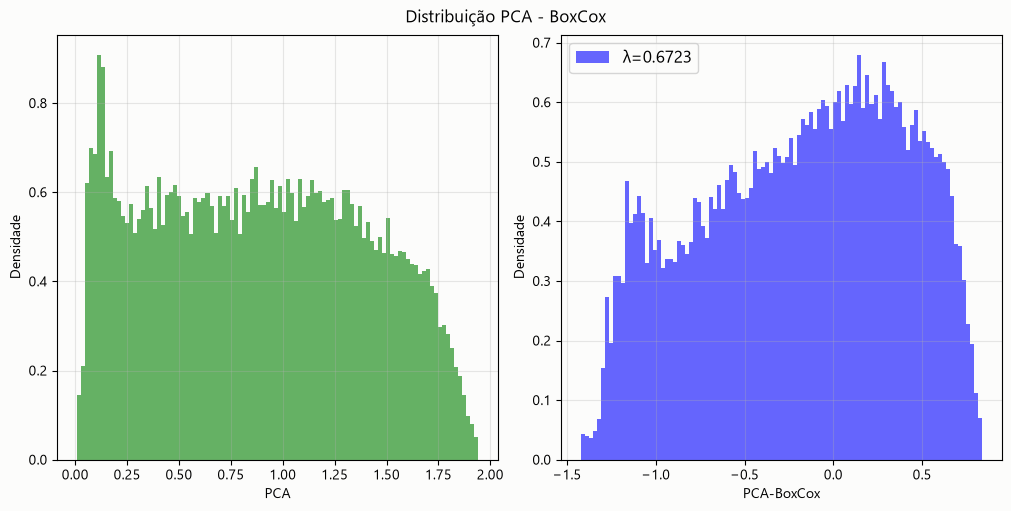

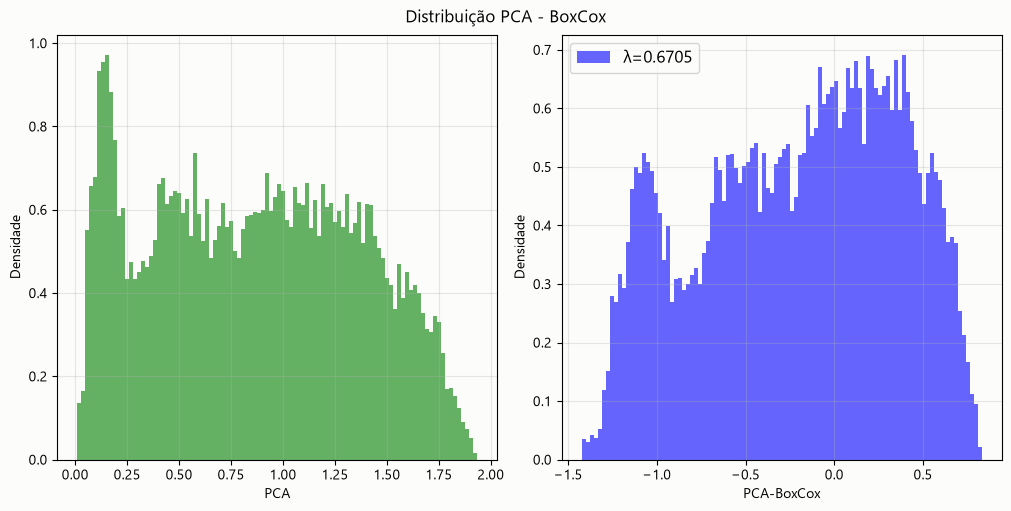

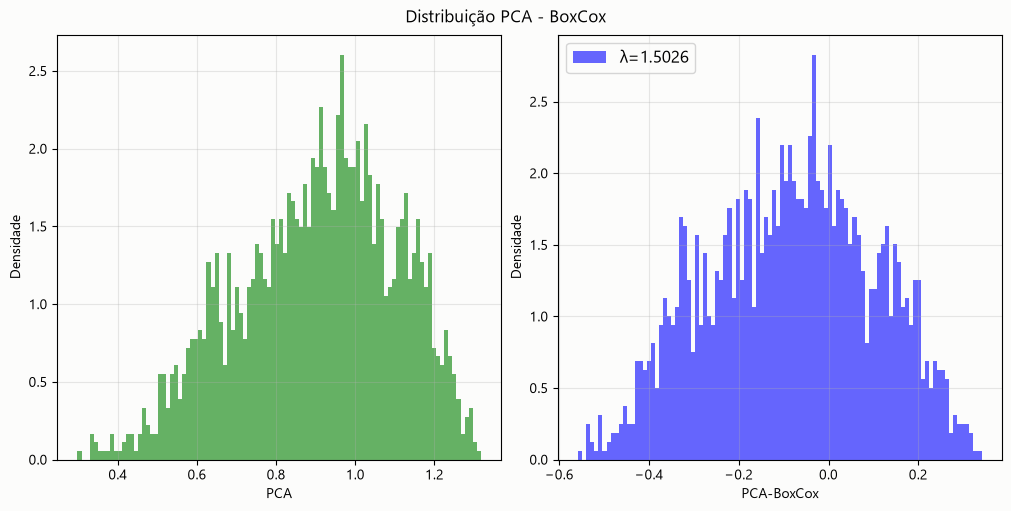

In [ ]:
from scipy import stats

intervals2 = ('5min', '10min', '30min', '1h', '1D')

for freq, d2 in ((i, frames[i]) for i in intervals2):
    fig, ax = plt.subplots(figsize=(10, 5), ncols=2, constrained_layout=True)
    d2 = d2[d2.PCA > 0].reset_index(drop=True)
    d2['PCA-BoxCox'], lmbda = stats.boxcox(d2['PCA'])
    
    ax[0].hist(d2['PCA'], bins=100, density=True, alpha=0.6, color='g')
    ax[0].set_xlabel("PCA")
    ax[0].set_ylabel("Densidade")
    ax[0].grid(alpha=0.3)

    ax[1].hist(d2['PCA-BoxCox'], bins=100, label=f"λ={lmbda:.4f}", density=True, alpha=0.6, color='b')
    ax[1].legend(loc="upper left", fontsize=12)
    ax[1].set_xlabel("PCA-BoxCox")
    ax[1].set_ylabel("Densidade")
    ax[1].grid(alpha=0.3)
    fig.savefig(IMG_DIR / f"pca_boxcox_distribution_{freq}.png")
    fig.suptitle("Distribuição PCA - BoxCox")
    fig.show()

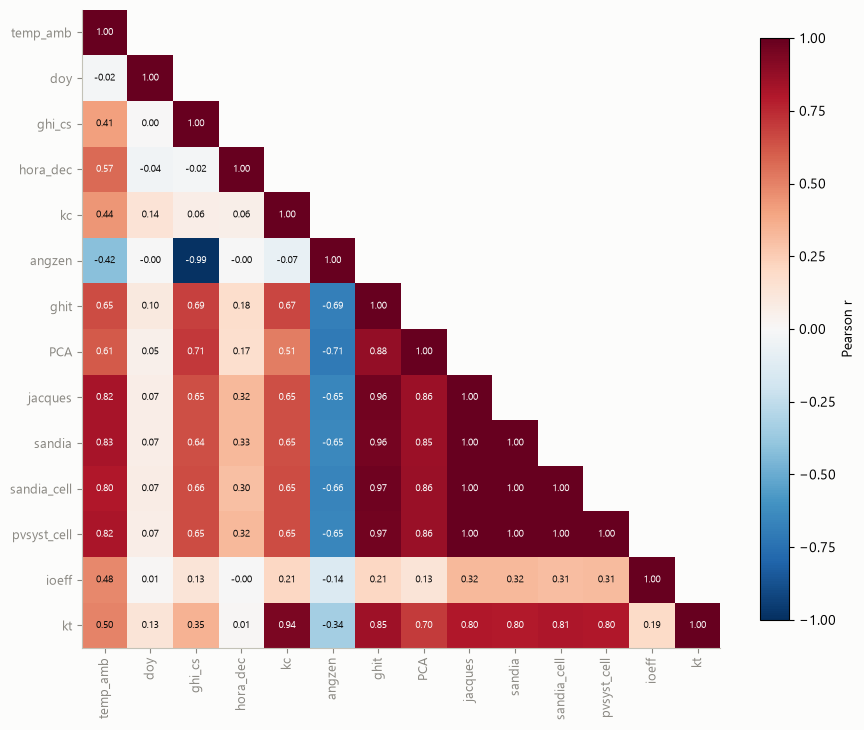

In [55]:
# Correlation matrix
corr_matrix = df.select_dtypes(include=[np.number]).corr()
# heatmap da matriz de correlacao (so o triangulo inferior; a matriz e' simetrica)
n = len(corr_matrix)
mask = np.triu(np.ones((n, n), dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr_matrix.mask(mask).to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(n), corr_matrix.columns, rotation=90)
ax.set_yticks(range(n), corr_matrix.index)
ax.set_aspect("equal")
enfeitar(ax, "", "", "")
ax.grid(False)

# anota o valor de Pearson dentro de cada celula
for r in range(n):
  for c in range(n):
    if c <= r:
      v = corr_matrix.iloc[r, c]
      ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
          color=SUPERFICIE if abs(v) > 0.5 else TINTA)

plt.colorbar(im, ax=ax, label="Pearson r", shrink=0.8)
plt.tight_layout()
plt.show()